IDs:
 - Student1 ID
 - Student2 ID

### **School of Computer Science, Reichman University**
## **Advanced Statistical Analysis and Model-Based Learning**
#### Fall 2026

#### Instructions:
- Write all teammates IDs at the top cell.
- Submit a copy of this notebook with code and answers filled in the relevant places as the solution of coding exercises.

# **Assignment 0: Exploratory Data Analysis**
#### Due: October 26 by 18:30


### Purpose
This assignment is a guided tutorial on **exploratory data analysis (EDA)**. The goal in EDA is not to perform a complete investigation of the dataset or to build a predictive model. Instead, you should become comfortable with the statistical and graphical tools that data scientistis and statisticians often use to extract meaning from data. At a high-level, the material of our class provides theoretical foundations to these practices. 


By the end of the assignment, you should be able to:
1. distinguish numerical, categorical, binary, and ordinal variables;
2. compute and interpret common summary statistics;
3. choose useful visualizations for distributions and relationships;
4. recognize skewness and the effect of simple transformations;
5. use scatterplots and correlation together rather than interchangeably;
6. compare distributions across groups;
7. treat missing and extreme observations as features of the data that require interpretation, not automatic deletion;
8. critically evaluate an automatically generated EDA report.

We will use a curated subset of the **Ames Housing** data introduced by De Cock (2011). The full dataset contains 2,930 residential property sales in Ames, Iowa, with more than 80 recorded attributes.


## 1. Setup and the curated Ames Housing data

The cell below downloads the raw Ames Housing data from a public mirror, keeps a deliberately small set of variables, renames them for readability, and writes the curated data to `ames_curated.csv`. 

The variables were selected to provide a mixture of:
- continuous numerical variables;
- discrete numerical variables;
- nominal categorical variables;
- ordinal variables;
- binary variables;
- a small amount of informative missingness.


In [1]:
# If needed, install the packages first:
# pip install pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')


In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/atiqahadryiana/AmesHousing/"
    "main/Ames_Housing_Data.csv"
)

raw = pd.read_csv(DATA_URL)

columns = {
    'SalePrice': 'sale_price',
    'Gr Liv Area': 'living_area',
    'Lot Area': 'lot_area',
    'Year Built': 'year_built',
    'Year Remod/Add': 'year_remodeled',
    'Overall Qual': 'overall_quality',
    'Overall Cond': 'overall_condition',
    'Bedroom AbvGr': 'bedrooms',
    'Full Bath': 'full_bathrooms',
    'Garage Cars': 'garage_capacity',
    'Garage Area': 'garage_area',
    'Total Bsmt SF': 'basement_area',
    'Neighborhood': 'neighborhood',
    'House Style': 'house_style',
    'Bldg Type': 'building_type',
    'Central Air': 'central_air',
    'Kitchen Qual': 'kitchen_quality',
    'Bsmt Qual': 'basement_quality',
    'Fireplaces': 'fireplaces',
    'Fireplace Qu': 'fireplace_quality',
}

dataset = raw[list(columns)].rename(columns=columns)
dataset.to_csv('ames_curated.csv', index=False)

print(dataset.shape)
dataset.head()


(2930, 20)


,sale_price,living_area,lot_area,year_built,year_remodeled,overall_quality,overall_condition,bedrooms,full_bathrooms,garage_capacity,garage_area,basement_area,neighborhood,house_style,building_type,central_air,kitchen_quality,basement_quality,fireplaces,fireplace_quality
0,215000,1656,31770,1960,1960,6,5,3,1,2.0,528.0,1080.0,NAmes,1Story,1Fam,Y,TA,TA,2,Gd
1,105000,896,11622,1961,1961,5,6,2,1,1.0,730.0,882.0,NAmes,1Story,1Fam,Y,TA,TA,0,NaN
2,172000,1329,14267,1958,1958,6,6,3,1,1.0,312.0,1329.0,NAmes,1Story,1Fam,Y,Gd,TA,0,NaN
3,244000,2110,11160,1968,1968,7,5,3,2,2.0,522.0,2110.0,NAmes,1Story,1Fam,Y,Ex,TA,2,TA
4,189900,1629,13830,1997,1998,5,5,3,2,2.0,482.0,928.0,Gilbert,2Story,1Fam,Y,TA,Gd,1,TA


### Variable dictionary

| Variable | Type | Description |
|---|---|---|
| `sale_price` | continuous | Sale price in US dollars |
| `living_area` | continuous | Above-ground living area, in square feet |
| `lot_area` | continuous | Lot size, in square feet |
| `year_built` | discrete numerical | Original construction year |
| `year_remodeled` | discrete numerical | Remodel year; equals construction year if no remodeling occurred |
| `overall_quality` | ordinal | Overall material and finish quality, coded 1–10 |
| `overall_condition` | ordinal | Overall condition, coded 1–10 |
| `bedrooms` | discrete numerical | Bedrooms above ground |
| `full_bathrooms` | discrete numerical | Full bathrooms above ground |
| `garage_capacity` | discrete numerical | Garage capacity in cars |
| `garage_area` | continuous | Garage area, in square feet |
| `basement_area` | continuous | Total basement area, in square feet |
| `neighborhood` | categorical | Neighborhood within Ames |
| `house_style` | categorical | Style of dwelling |
| `building_type` | categorical | Type of dwelling |
| `central_air` | binary categorical | Central air conditioning (`Y`/`N`) |
| `kitchen_quality` | ordinal categorical | Kitchen quality (`Ex`, `Gd`, `TA`, `Fa`, `Po`) |
| `basement_quality` | ordinal categorical | Basement height/quality; missing often means no basement |
| `fireplaces` | discrete numerical | Number of fireplaces |
| `fireplace_quality` | ordinal categorical | Fireplace quality; missing often means no fireplace |

**Question 1.1.** Why should `overall_quality` be regarded as ordinal rather than as an ordinary continuous measurement? What information is implied by the coding 1–10, and what information is *not* implied?


### Inspecting the structure

Before computing summaries, first look at the data representation itself.


In [3]:
dataset.head(10)


,sale_price,living_area,lot_area,year_built,year_remodeled,overall_quality,overall_condition,bedrooms,full_bathrooms,garage_capacity,garage_area,basement_area,neighborhood,house_style,building_type,central_air,kitchen_quality,basement_quality,fireplaces,fireplace_quality
0,215000,1656,31770,1960,1960,6,5,3,1,2.0,528.0,1080.0,NAmes,1Story,1Fam,Y,TA,TA,2,Gd
1,105000,896,11622,1961,1961,5,6,2,1,1.0,730.0,882.0,NAmes,1Story,1Fam,Y,TA,TA,0,NaN
2,172000,1329,14267,1958,1958,6,6,3,1,1.0,312.0,1329.0,NAmes,1Story,1Fam,Y,Gd,TA,0,NaN
3,244000,2110,11160,1968,1968,7,5,3,2,2.0,522.0,2110.0,NAmes,1Story,1Fam,Y,Ex,TA,2,TA
4,189900,1629,13830,1997,1998,5,5,3,2,2.0,482.0,928.0,Gilbert,2Story,1Fam,Y,TA,Gd,1,TA
5,195500,1604,9978,1998,1998,6,6,3,2,2.0,470.0,926.0,Gilbert,2Story,1Fam,Y,Gd,TA,1,Gd
6,213500,1338,4920,2001,2001,8,5,2,2,2.0,582.0,1338.0,StoneBr,1Story,TwnhsE,Y,Gd,Gd,0,NaN
7,191500,1280,5005,1992,1992,8,5,2,2,2.0,506.0,1280.0,StoneBr,1Story,TwnhsE,Y,Gd,Gd,0,NaN
8,236500,1616,5389,1995,1996,8,5,2,2,2.0,608.0,1595.0,StoneBr,1Story,TwnhsE,Y,Gd,Gd,1,TA
9,189000,1804,7500,1999,1999,7,5,3,2,2.0,442.0,994.0,Gilbert,2Story,1Fam,Y,Gd,TA,1,TA


In [4]:
dataset.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sale_price         2930 non-null   int64  
 1   living_area        2930 non-null   int64  
 2   lot_area           2930 non-null   int64  
 3   year_built         2930 non-null   int64  
 4   year_remodeled     2930 non-null   int64  
 5   overall_quality    2930 non-null   int64  
 6   overall_condition  2930 non-null   int64  
 7   bedrooms           2930 non-null   int64  
 8   full_bathrooms     2930 non-null   int64  
 9   garage_capacity    2929 non-null   float64
 10  garage_area        2929 non-null   float64
 11  basement_area      2929 non-null   float64
 12  neighborhood       2930 non-null   object 
 13  house_style        2930 non-null   object 
 14  building_type      2930 non-null   object 
 15  central_air        2930 non-null   object 
 16  kitchen_quality    2930 

In [5]:
dataset.nunique().sort_values()


central_air             2
fireplace_quality       5
basement_quality        5
kitchen_quality         5
building_type           5
fireplaces              5
full_bathrooms          5
garage_capacity         6
house_style             8
bedrooms                8
overall_condition       9
overall_quality        10
neighborhood           28
year_remodeled         61
year_built            118
garage_area           603
sale_price           1032
basement_area        1058
living_area          1292
lot_area             1960
dtype: int64

**Question 1.2.** Choose two variables that Pandas stores as numbers but that should not automatically be treated as ordinary continuous measurements. Explain briefly.


## 2. Numerical summaries

A numerical summary compresses a sample into a small number of quantities. This can be useful, but it necessarily discards information.

For a numerical sample $x_1,\ldots,x_n$, common summaries include:
- **mean**: $\bar{x}:=n^{-1}\sum_{i=1}^n x_i$;
- **median**: the middle order statistic (or average of the two middle values);
- **standard deviation**: the square root of the average squared deviation from the mean;
$$
STD := \sqrt{ \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2}
$$
- **quantiles**: values that describe specified positions in the ordered sample. The $0.5$-th quantile is the median. 
- **interquartile range (IQR)**: $Q_{0.75}-Q_{0.25}$;


The mean and standard deviation are particularly natural for approximately symmetric distributions without very heavy tails. The median and IQR are less sensitive to extreme observations, thus are often preffered if the data have heavy tails. 


In [6]:
numeric_cols = [
    'sale_price', 'living_area', 'lot_area', 'year_built', 'year_remodeled',
    'overall_quality', 'overall_condition', 'bedrooms', 'full_bathrooms',
    'garage_capacity', 'garage_area', 'basement_area', 'fireplaces'
]

dataset[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
sale_price,2930.0,180796.060068,79886.692357,12789.0,129500.00,160000.0,213500.00,755000.0
living_area,2930.0,1499.690444,505.508887,334.0,1126.00,1442.0,1742.75,5642.0
lot_area,2930.0,10147.921843,7880.017759,1300.0,7440.25,9436.5,11555.25,215245.0
year_built,2930.0,1971.356314,30.245361,1872.0,1954.00,1973.0,2001.00,2010.0
year_remodeled,2930.0,1984.266553,20.860286,1950.0,1965.00,1993.0,2004.00,2010.0
overall_quality,2930.0,6.094881,1.411026,1.0,5.00,6.0,7.00,10.0
overall_condition,2930.0,5.563140,1.111537,1.0,5.00,5.0,6.00,9.0
bedrooms,2930.0,2.854266,0.827731,0.0,2.00,3.0,3.00,8.0
full_bathrooms,2930.0,1.566553,0.552941,0.0,1.00,2.0,2.00,4.0
garage_capacity,2929.0,1.766815,0.760566,0.0,1.00,2.0,2.00,5.0


In [7]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

summary = dataset[numeric_cols].agg(['mean', 'median', 'std', iqr, 'min', 'max']).T
summary


,mean,median,std,iqr,min,max
sale_price,180796.060068,160000.0,79886.692357,84000.00,12789.0,755000.0
living_area,1499.690444,1442.0,505.508887,616.75,334.0,5642.0
lot_area,10147.921843,9436.5,7880.017759,4115.00,1300.0,215245.0
year_built,1971.356314,1973.0,30.245361,47.00,1872.0,2010.0
year_remodeled,1984.266553,1993.0,20.860286,39.00,1950.0,2010.0
overall_quality,6.094881,6.0,1.411026,2.00,1.0,10.0
overall_condition,5.563140,5.0,1.111537,1.00,1.0,9.0
bedrooms,2.854266,3.0,0.827731,1.00,0.0,8.0
full_bathrooms,1.566553,2.0,0.552941,1.00,0.0,4.0
garage_capacity,1.766815,2.0,0.760566,1.00,0.0,5.0


**Question 2.1.** Compare the mean and median of `sale_price` and of `lot_area`. What does the difference suggest about the shapes of these distributions?

**Question 2.2.** For `sale_price`, compare the standard deviation and the IQR. Why should neither quantity be interpreted without looking at the distribution itself?


### Categorical summaries

For categorical variables, counts and proportions are usually more meaningful than arithmetic summaries.


In [8]:
dataset['house_style'].value_counts()


house_style
1Story    1481
2Story     873
1.5Fin     314
SLvl       128
SFoyer      83
2.5Unf      24
1.5Unf      19
2.5Fin       8
Name: count, dtype: int64

In [9]:
dataset['central_air'].value_counts(normalize=True).rename('proportion')


central_air
Y    0.933106
N    0.066894
Name: proportion, dtype: float64

**Exercise 2.3.** Produce counts and proportions for `kitchen_quality`. Present the categories in their natural quality order rather than alphabetically.


In [ ]:
# Your code here


## 3. Visualizing a single distribution

A summary statistic is never a complete description of a distribution. Histograms, empirical cumulative distribution functions (ECDFs), and boxplots show different aspects of the same sample.

### Histogram
A histogram groups numerical observations into intervals (bins) and displays the number or proportion falling into each interval. The appearance depends on the binning choice.


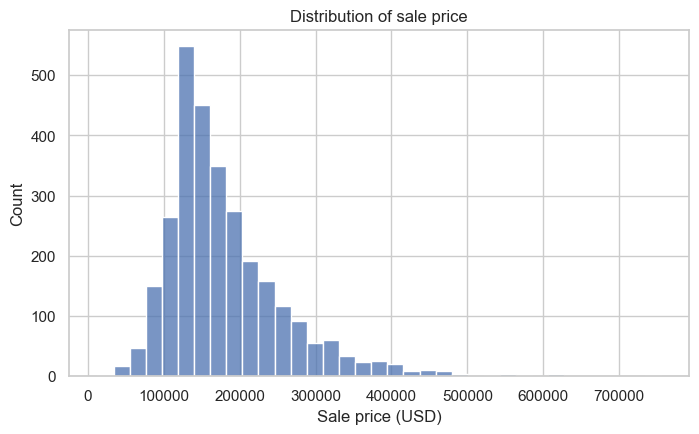

In [10]:
plt.figure(figsize=(8, 4.5))
sns.histplot(data=dataset, x='sale_price', bins=35)
plt.title('Distribution of sale price')
plt.xlabel('Sale price (USD)')
plt.show()


### ECDF
The empirical CDF at a value $x$ is the fraction of observations less than or equal to $x$. Unlike a histogram, it does not require choosing bins.


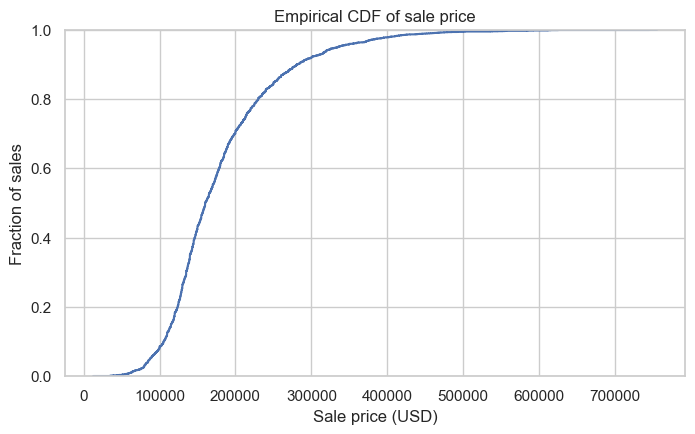

In [11]:
plt.figure(figsize=(8, 4.5))
sns.ecdfplot(data=dataset, x='sale_price')
plt.title('Empirical CDF of sale price')
plt.xlabel('Sale price (USD)')
plt.ylabel('Fraction of sales')
plt.show()


### Boxplot
A boxplot emphasizes the median, quartiles, and observations lying far beyond the central part of the sample. The conventional whisker rule is a graphical convention; points beyond the whiskers are not automatically errors or observations that should be removed.


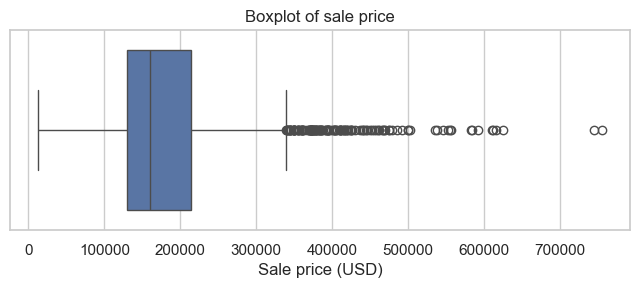

In [12]:
plt.figure(figsize=(8, 2.6))
sns.boxplot(data=dataset, x='sale_price')
plt.title('Boxplot of sale price')
plt.xlabel('Sale price (USD)')
plt.show()


**Question 3.1.** What features of the `sale_price` distribution are visible in the histogram but not in the mean and standard deviation alone?

**Exercise 3.2.** Draw a histogram and an ECDF for `lot_area`. Try at least two reasonable histogram bin choices. Which features are stable across the choices?


In [ ]:
# Your code here


### A short cautionary example: identical summaries, different data

The four datasets below are Anscombe's quartet. They were constructed to have nearly identical means, variances, correlations, and least-squares regression lines.


In [18]:
anscombe = pd.DataFrame({
    'x1': [10,8,13,9,11,14,6,4,12,7,5],
    'y1': [8.04,6.95,7.58,8.81,8.33,9.96,7.24,4.26,10.84,4.82,5.68],
    'x2': [10,8,13,9,11,14,6,4,12,7,5],
    'y2': [9.14,8.14,8.74,8.77,9.26,8.10,6.13,3.10,9.13,7.26,4.74],
    'x3': [10,8,13,9,11,14,6,4,12,7,5],
    'y3': [7.46,6.77,12.74,7.11,7.81,8.84,6.08,5.39,8.15,6.42,5.73],
    'x4': [8,8,8,8,8,8,8,19,8,8,8],
    'y4': [6.58,5.76,7.71,8.84,8.47,7.04,5.25,12.50,5.56,7.91,6.89],
})

for j in range(1, 5):
    x, y = anscombe[f'x{j}'], anscombe[f'y{j}']
    print(j, {
        'mean_x': x.mean(), 'mean_y': y.mean(),
        'sd_x': x.std(), 'sd_y': y.std(),
        'corr': x.corr(y)
    })


1 {'mean_x': 9.0, 'mean_y': 7.500909090909093, 'sd_x': 3.3166247903554, 'sd_y': 2.031568135925815, 'corr': 0.81642051634484}
2 {'mean_x': 9.0, 'mean_y': 7.50090909090909, 'sd_x': 3.3166247903554, 'sd_y': 2.0316567355016177, 'corr': 0.8162365060002428}
3 {'mean_x': 9.0, 'mean_y': 7.5, 'sd_x': 3.3166247903554, 'sd_y': 2.030423601123667, 'corr': 0.8162867394895984}
4 {'mean_x': 9.0, 'mean_y': 7.500909090909091, 'sd_x': 3.3166247903554, 'sd_y': 2.0305785113876023, 'corr': 0.8165214368885028}


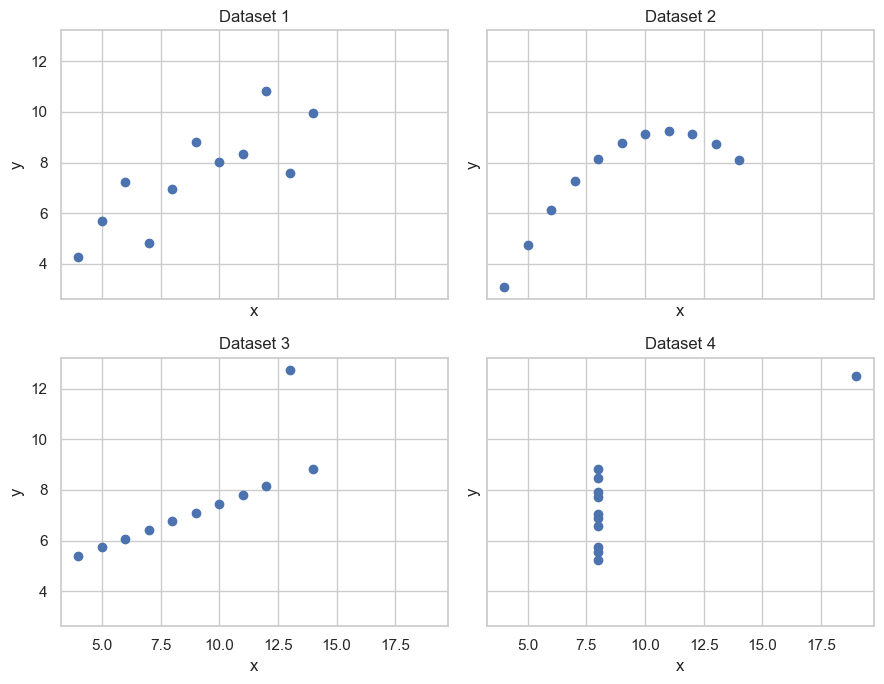

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
for j, ax in enumerate(axes.flat, start=1):
    ax.scatter(anscombe[f'x{j}'], anscombe[f'y{j}'])
    ax.set_title(f'Dataset {j}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
plt.tight_layout()
plt.show()


**Question 3.3.** What lesson does Anscombe's quartet illustrate about the relationship between numerical summaries and visualization?


## 4. Skewness and transformations

Many positive-valued measurements have a long right tail. A logarithmic transformation can make multiplicative differences easier to compare and can compress extreme upper values.

A transformation is not automatically an "improvement"; it changes the scale on which differences are being studied. Always state which scale you are using.


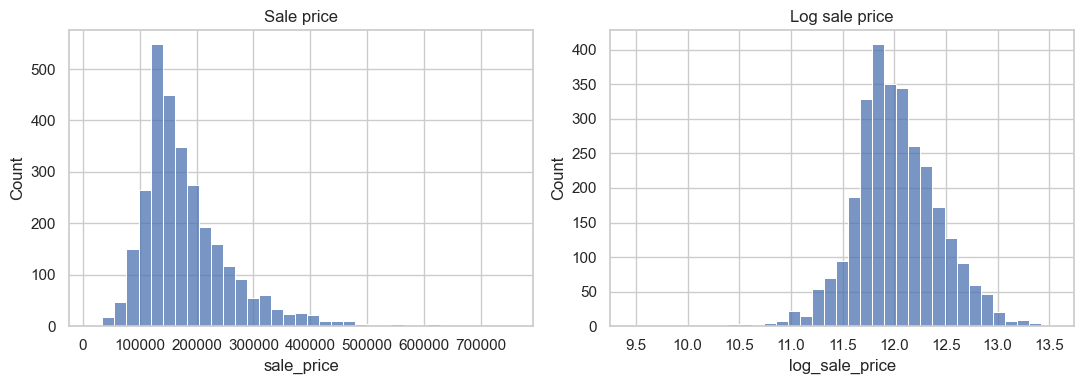

In [20]:
dataset['log_sale_price'] = np.log(dataset['sale_price'])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=dataset, x='sale_price', bins=35, ax=axes[0])
axes[0].set_title('Sale price')

sns.histplot(data=dataset, x='log_sale_price', bins=35, ax=axes[1])
axes[1].set_title('Log sale price')

plt.tight_layout()
plt.show()


In [21]:
dataset[['sale_price', 'log_sale_price']].agg(['mean', 'median', 'std', 'skew'])


,sale_price,log_sale_price
mean,180796.060068,12.020969
median,160000.000000,11.982929
std,79886.692357,0.407587
skew,1.743500,-0.014793


**Question 4.1.** Describe the effect of the logarithm on the shape of the `sale_price` distribution.

**Question 4.2.** On the original scale, a change from \$100,000 to \$150,000 and a change from \$500,000 to \$550,000 are equal differences. Are they equally large on the log scale? Explain what distinction the two scales emphasize.

**Exercise 4.3.** Repeat the comparison for `lot_area`. Is a log transformation similarly useful there?


In [ ]:
# Your code here


## 5. Relationships between numerical variables

For two numerical variables, the scatterplot should usually be examined before—or at least together with—a correlation coefficient.

The sample Pearson correlation coefficient is

$$
r = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}.
$$

It measures **linear association**. A value close to zero does not imply that the variables are unrelated, and a large magnitude does not imply causation.


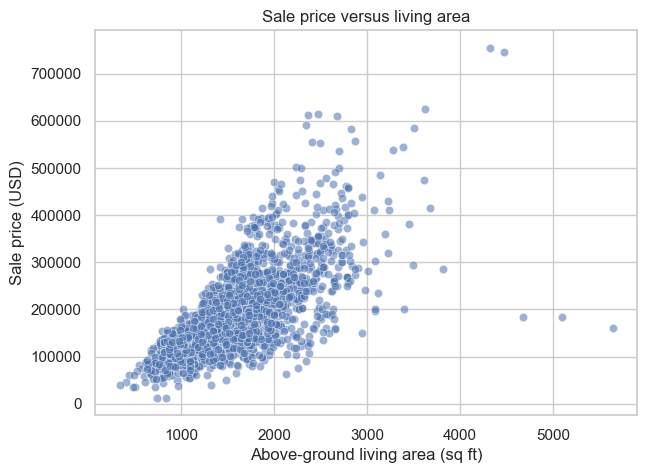

In [22]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=dataset, x='living_area', y='sale_price', alpha=0.55)
plt.title('Sale price versus living area')
plt.xlabel('Above-ground living area (sq ft)')
plt.ylabel('Sale price (USD)')
plt.show()


In [23]:
dataset[['living_area', 'sale_price']].corr()


,living_area,sale_price
living_area,1.00000,0.70678
sale_price,0.70678,1.00000


**Question 5.1.** Describe the relationship visible in the scatterplot. Mention direction, strength, shape, and any observations that deserve attention.

**Question 5.2.** Does the correlation coefficient capture everything you described in Question 5.1? Why or why not?

**Exercise 5.3.** Compare the following three relationships using both scatterplots and Pearson correlations:
- `garage_area` versus `sale_price`;
- `year_built` versus `sale_price`;
- `lot_area` versus `sale_price`.

For which pair is the correlation coefficient the most adequate one-number summary of the displayed relationship? Briefly justify your answer.


In [ ]:
# Your code here


### Correlation matrices

A correlation matrix can be a useful compact index of pairwise linear associations among numerical variables. It is not a replacement for inspecting important scatterplots.


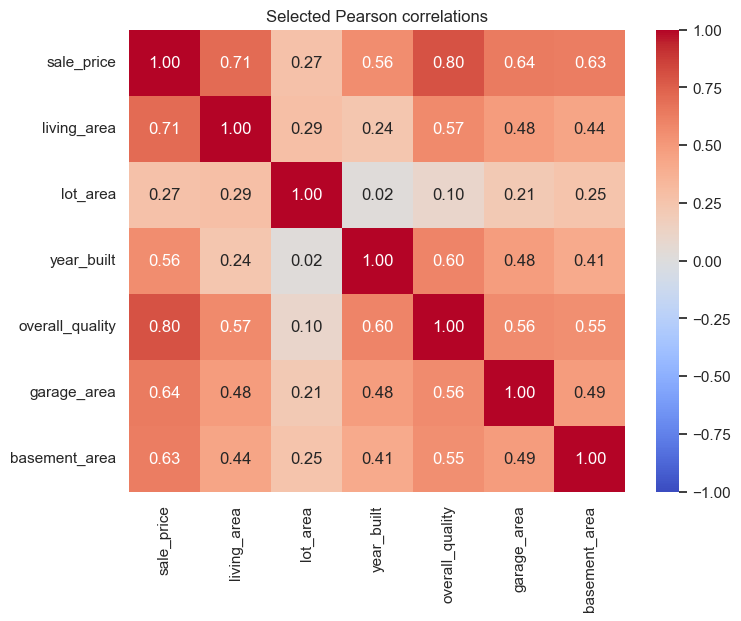

In [24]:
selected = [
    'sale_price', 'living_area', 'lot_area', 'year_built',
    'overall_quality', 'garage_area', 'basement_area'
]

corr = dataset[selected].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Selected Pearson correlations')
plt.show()


**Question 5.4.** Choose one entry in the correlation matrix that you would *not* want to interpret without first seeing the corresponding plot. Produce the plot and explain why.


In [ ]:
# Your code here


## 6. Comparing distributions across groups

When one variable is categorical (or ordinal) and another is numerical, useful displays include side-by-side boxplots, violin plots, strip plots, and grouped numerical summaries.


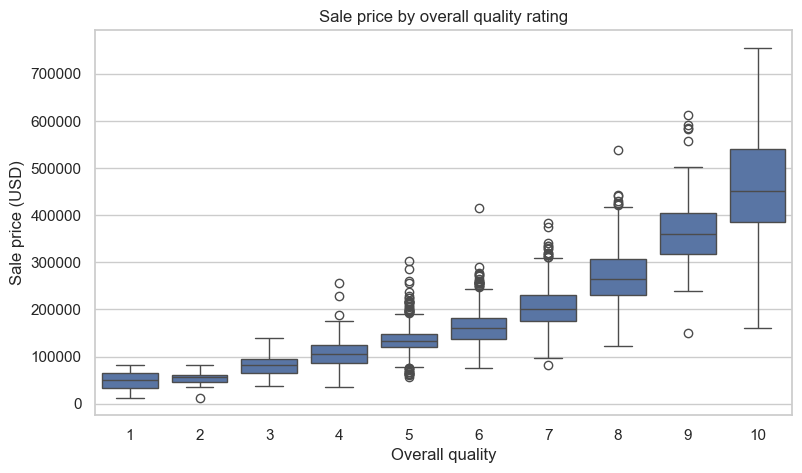

In [25]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=dataset, x='overall_quality', y='sale_price')
plt.title('Sale price by overall quality rating')
plt.xlabel('Overall quality')
plt.ylabel('Sale price (USD)')
plt.show()


In [26]:
dataset.groupby('overall_quality')['sale_price'].agg(['count', 'mean', 'median', 'std'])


,count,mean,median,std
overall_quality,,,,
1,4,48725.000000,50150.0,29341.935292
2,13,52325.307692,57625.0,17562.955704
3,40,83185.975000,81200.0,23569.801683
4,226,106485.097345,105000.0,29224.943495
5,825,134752.516364,133000.0,27690.596654
6,732,162130.318306,159500.0,37201.296411
7,602,205025.760797,200000.0,43166.268562
8,350,270913.594286,264530.5,61326.207415
9,107,368336.766355,360000.0,79201.265422


**Question 6.1.** What does the boxplot show that the table of group means alone does not?

**Exercise 6.2.** Compare `sale_price` across `central_air` categories using an appropriate plot and at least two numerical summaries.

**Exercise 6.3.** Choose either `house_style` or `neighborhood`. Produce a plot comparing sale-price distributions across categories. If there are many categories, order or restrict them in a way that makes the figure readable, and state what you did.


In [ ]:
# Your code here


### Looking at a relationship within groups

A marginal relationship can combine observations from groups with different typical levels. A simple grouped plot is often enough to see whether the same relationship looks similar across groups.


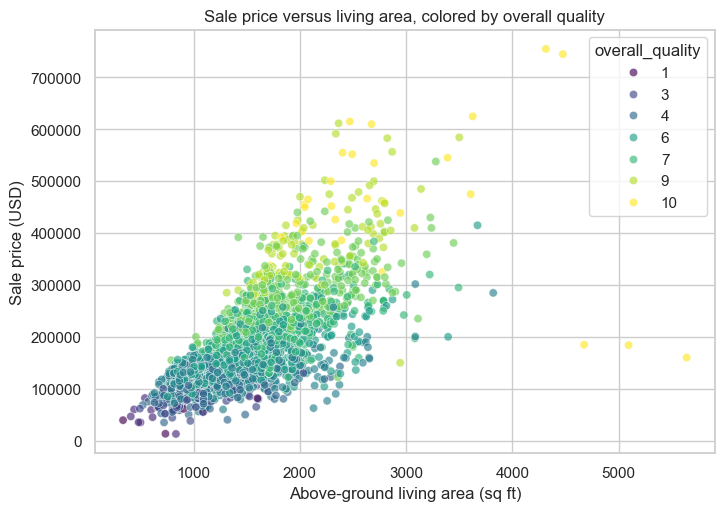

In [27]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(
    data=dataset,
    x='living_area',
    y='sale_price',
    hue='overall_quality',
    palette='viridis',
    alpha=0.65
)
plt.title('Sale price versus living area, colored by overall quality')
plt.xlabel('Above-ground living area (sq ft)')
plt.ylabel('Sale price (USD)')
plt.show()


**Question 6.4.** What additional structure becomes visible after showing `overall_quality`? You do not need to fit a model; describe only what the plot suggests.


## 7. Missing values and unusual observations

Missing values and extreme observations should be identified early, but there is no general rule that they should be deleted.

A missing value can mean, among other possibilities:
- a measurement was not recorded;
- the quantity is not applicable;
- the information is unavailable for a systematic reason.

Likewise, an extreme observation may be an error, but it may also be a perfectly valid member of the population.


In [28]:
missing = dataset.isna().sum().sort_values(ascending=False)
missing[missing > 0]


fireplace_quality    1422
basement_quality       80
garage_area             1
basement_area           1
garage_capacity         1
dtype: int64

In these data, missing `fireplace_quality` commonly corresponds to a home with **no fireplace**, and missing `basement_quality` commonly corresponds to a home with **no basement**. Thus, replacing all missing values by a column mean—or simply deleting every incomplete row—would not be a neutral operation.

**Question 7.1.** Verify the relationship between `fireplaces` and missing `fireplace_quality` using a contingency table. A contingency table is a cross-tabulation that shows the frequency distribution of variables—in this case, it will display the number of homes for each value of `fireplaces` split by whether `fireplace_quality` is missing or present.


In [ ]:
# Your code here


### Unusual observations

The conventional boxplot rule flags observations beyond 1.5 IQR from the nearest quartile. Treat this as a way to *locate observations for inspection*, not as a definition of bad data.


In [29]:
q1 = dataset['living_area'].quantile(0.25)
q3 = dataset['living_area'].quantile(0.75)
i = q3 - q1

flagged = dataset[
    (dataset['living_area'] < q1 - 1.5 * i) |
    (dataset['living_area'] > q3 + 1.5 * i)
]

flagged[['living_area', 'sale_price', 'overall_quality', 'neighborhood']].sort_values(
    'living_area', ascending=False
).head(10)


,living_area,sale_price,overall_quality,neighborhood
1498,5642,160000,10,Edwards
2180,5095,183850,10,Edwards
2181,4676,184750,10,Edwards
1760,4476,745000,10,NoRidge
1767,4316,755000,10,NoRidge
1497,3820,284700,5,Edwards
2737,3672,415000,6,Edwards
2445,3627,625000,10,NoRidge
2666,3608,475000,10,OldTown
2450,3500,584500,9,NoRidge


**Question 7.2.** Revisit the scatterplot of `living_area` versus `sale_price`. Would you automatically delete the observations flagged above? Give a statistical reason for your answer.

**Exercise 7.3.** Compute the correlation between `living_area` and `sale_price` both with and without the two largest `living_area` observations. Report both values. The purpose is not to decide which value is "correct", but to see whether a familiar summary is sensitive to a few unusual observations.


In [ ]:
# Your code here


## 8. LLM-generated EDA report

Modern analysis tools can generate summaries and visualizations automatically. This can save time, but statistical choices still need to be evaluated by a person who understands what the summaries mean.

For this exercise, use the file `ames_curated.csv` generated at the beginning of the notebook.

### Task
Upload `ames_curated.csv` to an LLM of your choice and ask it to produce a **self-contained HTML exploratory data analysis report**.

Your request should make clear that:
- the report is for a statistician encountering the dataset for the first time;
- it should include numerical summaries and visualizations of important distributions and relationships;
- it should identify missing values and unusual observations without automatically deleting them;
- it should remain exploratory: **do not ask for prediction models, hypothesis tests, or causal conclusions**;
- the final deliverable should be a **single HTML file**, with figures embedded so that it can be opened locally without relying on external files.

You may formulate the prompt in your own way. Include the prompt you used in your submission.

### Evaluate the report
Answer the following:

**8.1. Effective choice.** Select one visualization or numerical summary from the generated report that you think is particularly effective. Explain what makes it appropriate for the variable(s) being summarized.

**8.2. Improve one choice.** Select one visualization or summary that you would change. Produce your own improved version and briefly explain why it is preferable.

**8.3. Evidence versus statement.** Identify one statement in the report that is not adequately supported by the numerical or graphical evidence shown. Explain what additional evidence would be needed, or rewrite the statement more cautiously.

Submit the generated HTML report together with your notebook.


## 9. Takeaways

- numerical summaries are useful, but are not substitutes for distributions;
- different plots answer different questions;
- transformations change the scale on which differences are compared;
- correlation summarizes linear association and should be interpreted together with a scatterplot;
- grouped summaries can reveal structure hidden by aggregate summaries;
- missing and extreme observations require interpretation before modification;
- automated analysis can generate plots and summaries, but the statistical judgment remains yours.

These habits will recur throughout the course when we begin fitting and evaluating statistical models.

### Data source
Dean De Cock (2011), *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project*, Journal of Statistics Education. The full Ames Housing dataset contains 2,930 property sales and 82 recorded fields. The `AmesHousing` R package maintained by Max Kuhn provides documented raw and processed versions of these data.
